# Part 2 — How Long Should an A/B Test Run? Power and Sample Size

In the previous part, we assigned users to groups and measured the metrics of each group. So far, so good. But how long should we run this test? And does the answer change depending on the metric we want to increase?

Spoiler: it does. In our example, for the same +5% effect, the answer is 52 days for conversion rate and 159 days for GMV.

This notebook contains all the calculations and simulations used in the article:

1. **Power** — If there is a real effect, how often does our test find it?
2. **What determines power?** → Effect size, sample size and variance
3. **Sample size** — How many users, and how many days, do we need?
4. **Peeking** — Why should we wait until the end?

In [1]:
import hashlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

N_USERS = 100_000
N_SIMS = 2_000
SALT = "checkout_button_color"

plt.rcParams.update({
    "figure.figsize": (8, 3.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
})
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"


def users_axis(ax):
    # log x-axis with readable tick labels (10k, 100k, 1M)
    ax.set_xscale("log")
    ax.set_xticks([10_000, 30_000, 100_000, 300_000, 1_000_000, 3_000_000])
    ax.set_xticklabels(["10k", "30k", "100k", "300k", "1M", "3M"])
    ax.minorticks_off()

## The data: users who can order more than once

In Part 1, every user could place at most one order. This time, the data is a bit closer to a real e-commerce site. Every user gets two persistent traits:

- **order rate**: how often the user orders. It is very uneven between users (a gamma distribution): most users almost never order, a few order often.
- **spend level**: the typical order value of the user (log-normal, median 80, like in Part 1).

Then we simulate the two weeks of the experiment. The number of orders of a user is random (Poisson), and each order value varies around the user's spend level. So a user can now place several orders. The data is still simulated.

We also simulate the two weeks *before* the experiment. We don't use them in this part, but we will need them in Part 3.

In [2]:
rng = np.random.default_rng(42)
sequential_ids = [str(i) for i in range(1, N_USERS + 1)]

# Persistent user traits
order_rate = rng.gamma(shape=0.03, scale=2.0, size=N_USERS)   # mean 0.06 orders per period, very uneven
spend_level = rng.lognormal(np.log(80), 0.6, N_USERS)          # the user's typical order value


def simulate_period(rng):
    n_orders = rng.poisson(order_rate)
    order_user = np.repeat(np.arange(N_USERS), n_orders)       # which user placed each order
    order_values = spend_level[order_user] * rng.lognormal(0, 0.7, order_user.size)
    gmv = np.zeros(N_USERS)
    np.add.at(gmv, order_user, order_values)
    return n_orders.astype(float), gmv


pre_orders, pre_gmv = simulate_period(rng)   # 2 weeks before the experiment (Part 3)
orders, gmv = simulate_period(rng)           # 2 weeks during the experiment

print(f"{'users':<25}: {N_USERS:,}")
print(f"{'users with an order':<25}: {(orders > 0).sum():,}")
print(f"{'orders':<25}: {int(orders.sum()):,}")
print(f"{'orders per buyer':<25}: {orders.sum() / (orders > 0).sum():.2f}")
print(f"{'CR':<25}: {(orders > 0).mean():.2%}")
print(f"{'mean GMV per user':<25}: {gmv.mean():.2f}")

users                    : 100,000
users with an order      : 3,265
orders                   : 6,169
orders per buyer         : 1.89
CR                       : 3.26%
mean GMV per user        : 7.45


We compare the groups with the same z-test as in Part 1. For each metric, the test needs two numbers per group: the metric's **value** and its **variance per user**. We use the same two metrics as in Part 1: CR and GMV.

In [3]:
def estimate(metric, gmv, orders):
    """Returns the metric's value and its variance per user."""
    if metric == "CR":                                  # binary
        p = (orders > 0).mean()
        return p, p * (1 - p)
    if metric == "GMV":                                 # continuous
        return gmv.mean(), gmv.var(ddof=1)


def z_test(metric, gmv, orders, in_b):
    """Returns the observed lift (%), the noise band (±%) and the p-value."""
    value_a, var_a = estimate(metric, gmv[~in_b], orders[~in_b])
    value_b, var_b = estimate(metric, gmv[in_b], orders[in_b])
    se = np.sqrt(var_a / (~in_b).sum() + var_b / in_b.sum())
    z = (value_b - value_a) / se
    return (value_b / value_a - 1) * 100, 1.96 * se / value_a * 100, 2 * stats.norm.sf(abs(z))

## Iteration 1 — Power: how often does a test find a real effect?

Basically, the "how long" question depends on how many users are assigned to the test (the **sample size**). It also depends on the effect we want to detect. For example, if we want to see whether the new variant is at least 50% better than the old one, we need far fewer users than for a 1% difference.

In the previous part, we worked on the GMV metric. With 100,000 users, its noise band was ±11.8%. A real 5% effect is inside this band, so with this sample size we will often conclude that there is no statistically significant difference between the two variants.

There is another problem: a test that we run only once may or may not detect the effect, just by chance. Let's examine this, as we did with the A/A test in the previous part. This time, we run two kinds of tests, 2,000 times each:

- **A/A test:** the same as in the previous part, as a reference.
- **Effect added to variant B:**
  - **CR +10%**: some extra users in group B place an order, so B's CR is 10% higher.
  - **GMV +5%**: every order in group B is 5% bigger.

At the end, we look at how many of these tests detect the effect.

In [4]:
TRUE_LIFT = {"CR": 0.10, "GMV": 0.05}


def add_effect(metric, lift, in_b, rng):
    g, o = gmv.copy(), orders.copy()
    if metric == "CR":
        p = (o[in_b] > 0).mean()
        new_buyers = in_b & (o == 0) & (rng.random(N_USERS) < lift * p / (1 - p))
        o[new_buyers] = 1                                   # extra buyers in B, one order each
        g[new_buyers] = spend_level[new_buyers]
    else:
        g[in_b] *= 1 + lift                                 # every order in B is bigger
    return g, o


def run_tests(metric, lift, n_sims=N_SIMS, seed=0):
    """Runs n_sims experiments with a random 50/50 split. Returns rows of (lift, band, p_value)."""
    sim_rng = np.random.default_rng(seed)
    results = []
    for _ in range(n_sims):
        split = sim_rng.random(N_USERS) < 0.5
        g, o = add_effect(metric, lift, split, sim_rng) if lift else (gmv, orders)
        results.append(z_test(metric, g, o, split))
    return np.array(results)


raw = {}


def simulation_table(metrics):
    rows = []
    for metric in metrics:
        for lift in [0.0, TRUE_LIFT[metric]]:
            res = run_tests(metric, lift)
            raw[(metric, lift)] = res
            significant = res[:, 2] < 0.05
            rows.append({
                "metric": metric,
                "true lift": f"{lift:+.0%}",
                "share significant": f"{significant.mean():.1%}",
                "avg. observed lift when significant": f"{res[significant, 0].mean():+.1f}%" if lift else "–",
            })
    return pd.DataFrame(rows)


simulation_table(["CR", "GMV"])

,metric,true lift,share significant,avg. observed lift when significant
0,CR,+0%,5.2%,–
1,CR,+10%,78.7%,+11.3%
2,GMV,+0%,4.5%,–
3,GMV,+5%,12.8%,+15.1%


The A/A test has a false positive rate of around 5%, which is expected when α = 0.05. The tests with an effect are different: **78.7%** of the tests detected the 10% effect on CR, but only **12.8%** of the tests detected the 5% effect on GMV.

The share of experiments where the test finds a real effect is called **power**. The industry standard is to aim for **80% power**. A real effect that the test misses is a **false negative**.

So we have two kinds of mistakes:

| | No real effect | Real effect |
|---|---|---|
| **Test says "significant"** | False positive (α, usually 5%) | Correct ✔ (power) |
| **Test says "not significant"** | Correct ✔ | False negative (1 − power) |

Let's also look at the last column of the table. When the GMV test is significant, the average observed lift is about +15%, much higher than the real 5% effect. Because the test has low power, mostly the experiments where random noise increased the observed lift become significant. This is called the **winner's curse**: a significant result from a test with low power often **overestimates** the real effect.

## Iteration 2 — What determines power?

So why is the GMV effect so much harder to detect than the CR effect? Three things can cause it:

1. **Effect size** → a bigger effect is much easier to detect. Here, GMV has a smaller effect (CR +10%, GMV +5%).
2. **Sample size** → more users make the noise band narrower. Both tests have 100,000 users, so this does not explain the difference here.
3. **Variance** → a higher variance means more noise, and GMV has a much higher variance than CR.

Do we need to run 2,000 tests (or even more) every time to calculate power? Fortunately, no. There is a formula for it:

```
power ≈ Φ( effect / SE − 1.96 )
```

- **Effect:** the real change we want to detect, for example a 5% increase in GMV.
- **SE (standard error):** how much our estimated effect can change between different samples. As a share of the mean, it is `CV × √(2 / n)`, where `CV = std / mean` and `n` is the number of users per group. A smaller SE makes it easier to detect the real effect.
- **1.96:** the critical value of a two-sided z-test when α = 0.05: the threshold for statistical significance.
- **Φ (Phi):** the cumulative distribution function of the standard normal distribution. It converts the result into a probability.

The most important part of the formula is `effect / SE`: it shows how large the real effect is compared to the noise in our measurement.

Let's calculate the power with the formula and compare it with the simulation results:

In [5]:
def relative_se(metric, n_per_group):
    value, var = estimate(metric, gmv, orders)
    return np.sqrt(var) / value * np.sqrt(2 / n_per_group)


def power(metric, effect, n_per_group, alpha=0.05):
    return stats.norm.cdf(effect / relative_se(metric, n_per_group) - stats.norm.ppf(1 - alpha / 2))


def check_formula(metrics):
    for metric in metrics:
        effect = TRUE_LIFT[metric]
        simulated = np.mean(raw[(metric, effect)][:, 2] < 0.05)
        print(f"{metric:<3} {effect:+.0%}: formula = {power(metric, effect, N_USERS // 2):.1%}   simulation = {simulated:.1%}")


check_formula(["CR", "GMV"])

CR  +10%: formula = 82.8%   simulation = 78.7%
GMV +5%: formula = 12.9%   simulation = 12.8%


The formula is close to the simulation (it is an approximation). Now we can see how power changes with the number of users for CR and GMV:

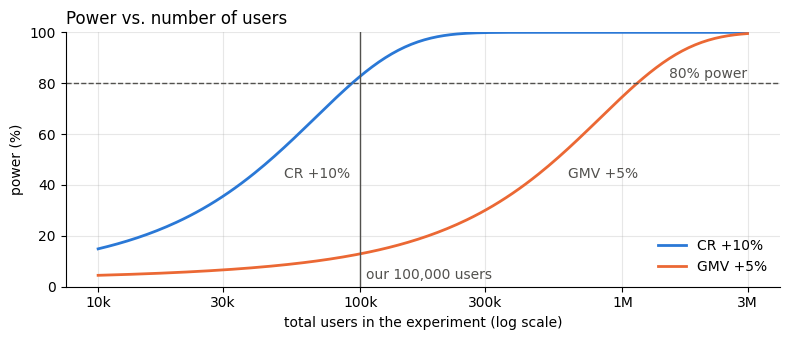

In [6]:
total_users = np.logspace(4, np.log10(3_000_000), 200)

fig, ax = plt.subplots()
for metric, color in [("CR", BLUE), ("GMV", ORANGE)]:
    effect = TRUE_LIFT[metric]
    curve = power(metric, effect, total_users / 2)
    ax.plot(total_users, curve * 100, color=color, linewidth=2, label=f"{metric} {effect:+.0%}")
    x_label = total_users[np.argmin(np.abs(curve - 0.5))]           # direct label where the curve crosses 50%
    ax.text(x_label * 1.12, 47, f"{metric} {effect:+.0%}", color=GRAY, ha="left", va="top")
ax.axhline(80, color=GRAY, linestyle="--", linewidth=1)
ax.text(3_000_000, 82, "80% power", color=GRAY, ha="right")
ax.axvline(N_USERS, color=GRAY, linewidth=1)
ax.text(N_USERS * 1.05, 3, "our 100,000 users", color=GRAY)
users_axis(ax)
ax.set_ylim(0, 100)
ax.set_xlabel("total users in the experiment (log scale)")
ax.set_ylabel("power (%)")
ax.set_title("Power vs. number of users", loc="left")
ax.legend(loc="lower right", frameon=False)
plt.tight_layout()
plt.show()

With 100,000 users, CR +10% already has around 80% power, but GMV +5% has a much lower power. We need many more users to detect a 5% change in GMV reliably.

Let's remember the GMV noise band from Part 1: with 100,000 users, it was about ±11.8%. To reach 80% power, the effect needs to be about `(1.96 + 0.84) / 1.96 ≈ 1.4` times this value. So with the same number of users, we need an effect of around 17% to reach 80% power.

The difference in variance comes from the type of the metric. CR is a binary metric: a user either places an order or not. GMV is a continuous metric, and some users spend much more than others. This creates more noise and makes smaller effects harder to detect.

## Iteration 3 — Sample size: how many users, and how many days?

Now we have everything we need to answer our question from the beginning: how many users do we need for an A/B test?

Instead of calculating the power for a given number of users, we can reverse the formula and calculate how many users we need for 80% power:

```
n per group = 2 × (1.96 + 0.84)² × CV² / effect²
```

- **n per group:** the number of users we need in each group, with a 50/50 split.
- **1.96:** comes from the 5% significance level (α = 0.05) of a two-sided test.
- **0.84:** comes from our target of 80% power.
- **CV (coefficient of variation):** how much the metric varies compared to its average value (`std / mean`).
- **Effect:** the relative change we want to detect. For example, 5% means 0.05, not 5.

The most important part is `CV² / effect²`: a metric with more noise needs more users, and a bigger effect needs fewer users.

But how do we calculate the CV? It depends on the metric type:

- **CR:** the calculation is simple; we only need the conversion rate: `CV² = (1 − CR) / CR`. For example, if CR is 10%, `CV² = (1 − 0.10) / 0.10 = 9`. A lower CR means a higher CV, so rare events need more users to detect the same relative effect.
- **GMV:** we need historical user-level data. Some users spend nothing, while others spend a lot. We calculate the mean and the variance of GMV per user and use them to find `CV²`.
- **AOV (average order value):** the calculation is a bit more complex, because it is a ratio: total GMV divided by total orders. We need to consider how GMV and the number of orders change together (the **delta method**). We will look at ratio metrics in a later part.

You don't need to remember every formula. The main idea is simple: different metrics have different levels of noise, and this affects how many users we need. Once we know the expected effect and the metric's variance, we can estimate the required sample size before starting the experiment.

The smallest effect we want to detect is called the **MDE (Minimum Detectable Effect)**. Choosing the MDE is a business decision: "Which improvement is big enough to matter to us?"

To answer the question "how long?", we need to convert the required number of users into days. In our example, around 100,000 users visit in two weeks, which means approximately **7,150 users per day**.

In [7]:
USERS_PER_DAY = N_USERS / 14


def sample_size_per_group(metric, mde, alpha=0.05, target_power=0.8):
    z = stats.norm.ppf(1 - alpha / 2) + stats.norm.ppf(target_power)
    value, var = estimate(metric, gmv, orders)
    cv2 = var / value**2
    return int(np.ceil(2 * z**2 * cv2 / mde**2))


rows = []
for metric in TRUE_LIFT:
    for mde in [0.02, 0.05, 0.10]:
        n = sample_size_per_group(metric, mde)
        rows.append({
            "metric": metric,
            "MDE": f"{mde:.0%}",
            "users per group": f"{n:,}",
            "total users": f"{2 * n:,}",
            "days": f"{2 * n / USERS_PER_DAY:,.0f}",
        })

pd.DataFrame(rows)

,metric,MDE,users per group,total users,days
0,CR,2%,"1,162,728","2,325,456",326
1,CR,5%,"186,037","372,074",52
2,CR,10%,"46,510","93,020",13
3,GMV,2%,"3,557,897","7,115,794",996
4,GMV,5%,"569,264","1,138,528",159
5,GMV,10%,"142,316","284,632",40


This is the answer to our question from the beginning: for the same +5% MDE, CR needs about **52 days**, while GMV needs about **159 days**. There are a few important points here:

- **GMV needs about 3 times more users than CR** for the same MDE. This comes from the difference in noise between the two metrics, as we discussed in Part 1.
- **Halving the MDE requires 4 times more users**, because the effect is squared in the formula. For example, detecting a +2% effect in GMV would require years of traffic (almost 1,000 days in our example).
- **Our +5% GMV example needs more than 10 times our 100,000 users.** This explains why the effect was difficult to detect in our simulation.

We can also ask the question the other way around: with the number of users we have, what is the smallest effect we can reliably detect?

In [8]:
z = stats.norm.ppf(0.975) + stats.norm.ppf(0.8)
for metric in TRUE_LIFT:
    mde = z * relative_se(metric, N_USERS // 2)
    print(f"{metric:<3}: with {N_USERS:,} users, the MDE at 80% power is about {mde:.1%}")

CR : with 100,000 users, the MDE at 80% power is about 9.6%
GMV: with 100,000 users, the MDE at 80% power is about 16.9%


> **Platform decision:** A platform should ask for the MDE when an experiment is created, calculate the needed sample size from each metric's historical variance, and show the expected **duration** before the experiment starts. This turns "how long should we run it?" from a guess into a calculation, and it is also the main protection against the next problem: peeking.

## Iteration 4 — Peeking: why should we wait?

We now know how to estimate the required sample size and how long an A/B test should run (ignoring factors like seasonality for now).

However, nothing stops us from building a dashboard that shows the lift and the p-value every day. We could check this dashboard daily and stop the experiment as soon as the result becomes statistically significant. This is called **peeking**, and stopping based on the result is known as **optional stopping**.

Let's look at this by changing the structure of the A/A test we used earlier. This time, new users join the experiment every day for 14 days. Instead of evaluating the test only at the end, we evaluate it every day, using all the data collected so far. For example, on day 2 we calculate the results with the data from days 1 and 2; on day 3, with the data from the first three days, and so on.

In [9]:
DAYS = 14


def daily_p_values(y, n_sims=N_SIMS, seed=1):
    """A/A tests where users arrive over DAYS days; returns the p-value after each day."""
    sim_rng = np.random.default_rng(seed)
    p_paths = np.empty((n_sims, DAYS))
    for s in range(n_sims):
        day = sim_rng.integers(0, DAYS, N_USERS)
        split = sim_rng.random(N_USERS) < 0.5
        cumulative = {}
        for name, mask in [("A", ~split), ("B", split)]:
            n = np.bincount(day[mask], minlength=DAYS).cumsum()
            s1 = np.bincount(day[mask], weights=y[mask], minlength=DAYS).cumsum()
            s2 = np.bincount(day[mask], weights=y[mask] ** 2, minlength=DAYS).cumsum()
            mean = s1 / n
            cumulative[name] = (n, mean, (s2 - n * mean**2) / (n - 1))
        (n_a, m_a, v_a), (n_b, m_b, v_b) = cumulative["A"], cumulative["B"]
        z = (m_b - m_a) / np.sqrt(v_a / n_a + v_b / n_b)
        p_paths[s] = 2 * stats.norm.sf(np.abs(z))
    return p_paths


paths = {"CR": daily_p_values((orders > 0).astype(float)), "GMV": daily_p_values(gmv)}

Let's look at one A/A test as an example:

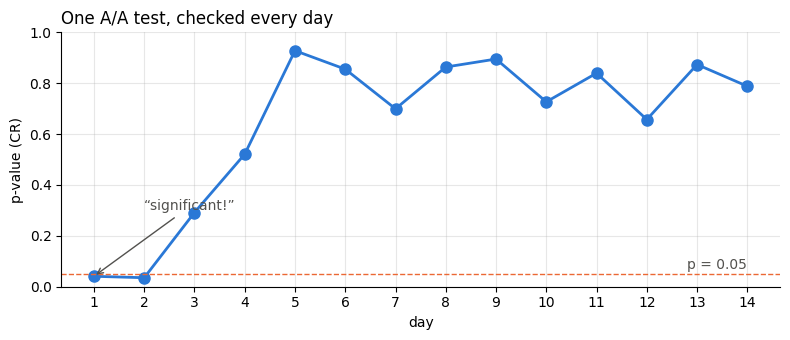

In [10]:
p = paths["CR"]
example = next(i for i in range(len(p)) if p[i, :7].min() < 0.05 and p[i, -1] > 0.5)
days = np.arange(1, DAYS + 1)

fig, ax = plt.subplots()
ax.plot(days, p[example], color=BLUE, linewidth=2, marker="o", markersize=8)
ax.axhline(0.05, color=ORANGE, linestyle="--", linewidth=1)
ax.text(DAYS, 0.07, "p = 0.05", color=GRAY, ha="right")
first = int(np.argmax(p[example] < 0.05))
ax.annotate("“significant!”", xy=(days[first], p[example, first]), xytext=(days[first] + 1, 0.3),
            color=GRAY, arrowprops=dict(arrowstyle="->", color=GRAY))
ax.set_xticks(days)
ax.set_ylim(0, 1)
ax.set_xlabel("day")
ax.set_ylabel("p-value (CR)")
ax.set_title("One A/A test, checked every day", loc="left")
plt.tight_layout()
plt.show()

In the first two days, the test result is statistically significant. However, if we continue the experiment, none of the remaining days shows a significant difference.

**Why?** The 5% significance level does not change from day to day: it stays the same for each single look. But **every extra look adds a new chance to be wrong**. Checking the results many times and stopping when they become significant increases the overall chance of a false positive.

The early days are the most dangerous. The result of each day is correlated with the previous days, because we use all the data collected so far. On day 14, our calculation includes the data of the previous 13 days, so one more day changes the result only a little. On day 2, we only have two days of data, so each new day changes the result a lot. Early looks are therefore less correlated with each other, and each of them is almost a new chance to be wrong.

### How much does peeking increase false positives?

Let's repeat our A/A test 2,000 times. This time, instead of checking the result only on day 14, we check it every day and count how many experiments become significant at least once:

In [11]:
rows = []
for metric, p in paths.items():
    rows.append({
        "metric": metric,
        "look once (day 14)": f"{np.mean(p[:, -1] < 0.05):.1%}",
        "look weekly (day 7, 14)": f"{np.mean((p[:, [6, 13]] < 0.05).any(axis=1)):.1%}",
        "look every day": f"{np.mean((p < 0.05).any(axis=1)):.1%}",
    })

pd.DataFrame(rows).set_index("metric")

,look once (day 14),"look weekly (day 7, 14)",look every day
metric,,,
CR,5.1%,8.2%,21.9%
GMV,4.3%,7.4%,20.7%


If we look only at the end, the false positive rate is about 5%, as expected. But if we look every day and stop at the first significant result, **about 1 in 5 A/A tests** declares a winner, even though nothing was changed.

### What can we do?

- The simplest solution is to **decide the experiment duration before it starts**, based on the required sample size, and make the decision only at the end.
- If the business needs to check the results during the experiment and maybe stop early, we can use methods designed for this, such as **sequential testing**, alpha spending or always-valid p-values. This is a topic for a later part.

> **Platform decision:** The platform can hide the p-value, or show a clear "too early" warning, until the planned sample size is reached. Here a product decision solves a statistics problem.

---

## Summary

In this part, we learned three important lessons about power, sample size and experiment duration:

1. **Think about power, not only false positives.** A test with low power can miss real effects. Even when its result is significant, it may overestimate the real effect (the winner's curse).
2. **Choose an MDE and calculate the sample size before starting the experiment.** Instead of guessing how long an experiment should run, we can calculate it from the MDE, the metric's variance and our daily traffic. In our example, GMV needs about 3 times more users than CR to detect the same relative effect.
3. **Decide the experiment duration in advance, and don't stop early.** Checking the results every day and stopping when they become significant raised the false positive rate from about 5% to about 20% in our simulation.

**What's next?** We have two ways to detect smaller effects: more users (a longer experiment) or less variance. In Part 3, we focus on the second option. We use historical user data from before the experiment for two purposes: first, to check whether our groups are balanced (**pre-test**), and then to reduce the noise in our metrics with **CUPED**.